In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import GroupShuffleSplit

In [ ]:
PROJECT_DIR = Path(
    r"D:\Pradeep Pandey\Nexvia Technology  Intership\Project 1"
)

DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "sample" / "images"
CSV_PATH = DATA_DIR / "sample" / "sample_labels.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("Available images:", len(list(IMAGE_DIR.glob("*.png"))))

In [5]:
disease_classes = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]


df["Finding Labels"] = df["Finding Labels"].apply(
    lambda x: x.split("|")
)


unknown_labels = set(
    label
    for labels in df["Finding Labels"]
    for label in labels
) - set(disease_classes) - {"No Finding"}

if unknown_labels:
    raise ValueError(f"Unexpected labels found: {unknown_labels}")


for disease in disease_classes:
    df[disease] = df["Finding Labels"].apply(
        lambda labels: int(disease in labels)
    )

print("Disease classes:", len(disease_classes))
print(df[disease_classes].head())

Disease classes: 14
   Atelectasis  Cardiomegaly  Effusion  Infiltration  Mass  Nodule  Pneumonia  \
0            0             0         0             1     0       0          0   
1            0             1         0             0     0       0          0   
2            0             0         0             0     0       0          0   
3            1             0         0             0     0       0          0   
4            0             1         1             0     0       0          0   

   Pneumothorax  Consolidation  Edema  Emphysema  Fibrosis  \
0             1              0      0          1         0   
1             0              0      0          1         0   
2             0              0      0          0         0   
3             0              0      0          0         0   
4             0              0      1          0         0   

   Pleural_Thickening  Hernia  
0                   1       0  
1                   0       0  
2                   0   

In [6]:
print("Disease-wise image counts:\n")
print(df[disease_classes].sum().sort_values(ascending=False))

print("\nImages with no disease finding:",
      (df[disease_classes].sum(axis=1) == 0).sum())

Disease-wise image counts:

Infiltration          967
Effusion              644
Atelectasis           508
Nodule                313
Mass                  284
Pneumothorax          271
Consolidation         226
Pleural_Thickening    176
Cardiomegaly          141
Emphysema             127
Edema                 118
Fibrosis               84
Pneumonia              62
Hernia                 13
dtype: int64

Images with no disease finding: 3044


In [9]:
 # Removing  rows with missing image files

df["Image Path"] = df["Image Index"].apply(
    lambda x: IMAGE_DIR / x
)


df = df[
    df["Image Path"].apply(lambda x: x.is_file())
].copy()

df = df.reset_index(drop=True)

print("Records after checking image files:", len(df))

Records after checking image files: 5606


In [11]:
#step 4 dataset splitting
from sklearn.model_selection import GroupShuffleSplit


split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

train_val_idx, test_idx = next(
    split_1.split(df, groups=df["Patient ID"])
)

train_val_df = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()



split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=1/9,
    random_state=42
)

train_idx, val_idx = next(
    split_2.split(
        train_val_df,
        groups=train_val_df["Patient ID"]
    )
)

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()


print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 4513
Validation images: 539
Testing images: 554


In [12]:
train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Patient-level data leakage check passed.")

print("\nTraining patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Testing patients:", len(test_patients))

Patient-level data leakage check passed.

Training patients: 3384
Validation patients: 423
Testing patients: 423


In [13]:
# step 5 image resizing and normalization
from torchvision import transforms

IMG_SIZE = 224

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

In [14]:

sample_row = train_df.iloc[0]

image_path = IMAGE_DIR / sample_row["Image Index"]


image = Image.open(image_path).convert("RGB")


processed_image = train_transform(image)

print("Original image size:", image.size)
print("Processed image shape:", processed_image.shape)
print("Data type:", processed_image.dtype)
print("Minimum pixel value:", processed_image.min().item())
print("Maximum pixel value:", processed_image.max().item())

Original image size: (1024, 1024)
Processed image shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum pixel value: -2.0836544036865234
Maximum pixel value: 2.1519827842712402


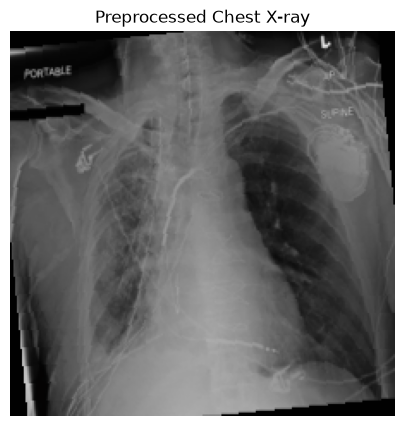

In [17]:
# Reverse normalization for visualization
mean = torch.tensor(imagenet_mean).view(3, 1, 1)
std = torch.tensor(imagenet_std).view(3, 1, 1)

display_image = processed_image * std + mean
display_image = display_image.clamp(0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(display_image.permute(1, 2, 0))
plt.title("Preprocessed Chest X-ray")
plt.axis("off")
plt.show()

In [19]:
# dataset loader and dataaset

class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, image_dir, classes, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.classes = classes
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = self.image_dir / row["Image Index"]

        image = Image.open(image_path).convert("RGB")

        labels = row[self.classes].to_numpy(dtype=np.float32)
        labels = torch.tensor(labels, dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, labels

train_dataset = ChestXrayDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    classes=disease_classes,
    transform=train_transform
)

val_dataset = ChestXrayDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    classes=disease_classes,
    transform=eval_transform
)

test_dataset = ChestXrayDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    classes=disease_classes,
    transform=eval_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 4513
Validation dataset: 539
Testing dataset: 554


In [20]:
sample_image, sample_label = train_dataset[0]

print("Image shape:", sample_image.shape)
print("Label shape:", sample_label.shape)
print("Image dtype:", sample_image.dtype)
print("Label dtype:", sample_label.dtype)
print("Labels:", sample_label)

Image shape: torch.Size([3, 224, 224])
Label shape: torch.Size([14])
Image dtype: torch.float32
Label dtype: torch.float32
Labels: tensor([0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0.])


In [22]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully.")
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

DataLoaders created successfully.
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16, 14])


In [23]:
SPLIT_DIR = PROJECT_DIR / "processed"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Dataset splits saved successfully.")
print("Location:", SPLIT_DIR)

Dataset splits saved successfully.
Location: D:\Pradeep Pandey\Nexvia Technology  Intership\Project 1\processed


In [24]:
import json

with open(SPLIT_DIR / "disease_classes.json", "w") as f:
    json.dump(disease_classes, f, indent=4)

print("Disease classes saved successfully.")

Disease classes saved successfully.


In [25]:
split_counts = pd.DataFrame({
    "Train": train_df[disease_classes].sum(),
    "Validation": val_df[disease_classes].sum(),
    "Test": test_df[disease_classes].sum()
})

display(split_counts)

,Train,Validation,Test
Atelectasis,424,43,41
Cardiomegaly,115,13,13
Effusion,526,51,67
Infiltration,797,77,93
Mass,233,28,23
Nodule,260,27,26
Pneumonia,47,7,8
Pneumothorax,214,32,25
Consolidation,191,12,23
Edema,93,6,19


In [ ]:
# Conclusion

Data preprocessing has been completed successfully.
Next Stage: DenseNet121 Model Development and Training.